# Clothes segmentation: evaluate a model and segment your own photos

Run this after a training run has produced a `best.pt`. It does not train anything.

1. `Runtime > Change runtime type`: choose **L4 GPU**. The training cells (7 and 8) do not fit a T4; cells 5 and 6 alone also work on a T4.
2. Set `RUN_NAME` in cell 1 to the run you want to look at.
3. Run the cells from top to bottom. Cell 3 asks for the new `clothseg_code.zip` once.

## 1. Settings

In [13]:
REPO_URL = ""  # leave empty to use the uploaded zip

DRIVE_ROOT = "/content/drive/MyDrive/clothseg"
CODE_DIR = "/content/clothes-segmentation"
CODE_VERSION = "9"
HEIGHT, WIDTH = 576, 384
SESSION_BUDGET_MIN = 600

RUN_NAME = "r1_segformer_b3"      # folder name inside <DRIVE_ROOT>/runs
CHECKPOINT = f"{DRIVE_ROOT}/runs/{RUN_NAME}/checkpoints/best.pt"

## 2. Mount Drive and show the environment

In [2]:
import os, platform, shutil, time
from google.colab import drive

drive.mount("/content/drive")
os.makedirs(DRIVE_ROOT, exist_ok=True)
SESSION_START = time.time()

def minutes_left():
    """Minutes of the session budget that remain; passed to every training command."""
    return max(1, SESSION_BUDGET_MIN - (time.time() - SESSION_START) / 60)

import torch, transformers
print("python      ", platform.python_version(), "| torch", torch.__version__, "| transformers", transformers.__version__)
print("GPU         ", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE: change the runtime type to a GPU")
if torch.cuda.is_available():
    print("GPU memory  ", f"{torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")
print("CPU cores   ", os.cpu_count())
print("local disk  ", f"{shutil.disk_usage('/content').free / 1024**3:.0f} GB free")
print("Drive       ", f"{shutil.disk_usage(DRIVE_ROOT).free / 1024**3:.0f} GB free")
assert torch.cuda.is_available(), "No GPU. Choose Runtime > Change runtime type > L4 GPU, then run again."

Mounted at /content/drive
python       3.13.15 | torch 2.11.0+cu130 | transformers 5.18.0
GPU          NVIDIA L4
GPU memory   22.0 GB
CPU cores    12
local disk   193 GB free
Drive        184 GB free


## 3. Get the code

In [14]:
import subprocess, zipfile

def code_version(folder):
    path = os.path.join(folder, "VERSION")
    return open(path).read().strip() if os.path.exists(path) else "1"

os.chdir("/content")
if REPO_URL:
    if os.path.isdir(f"{CODE_DIR}/.git"):
        print(subprocess.run(["git", "-C", CODE_DIR, "pull"], capture_output=True, text=True).stdout)
    else:
        r = subprocess.run(["git", "clone", REPO_URL, CODE_DIR], capture_output=True, text=True)
        assert r.returncode == 0, f"git clone failed. Is the URL correct and the repository public?\n{r.stderr}"
elif os.path.isdir(f"{DRIVE_ROOT}/code") and code_version(f"{DRIVE_ROOT}/code") == CODE_VERSION:
    shutil.rmtree(CODE_DIR, ignore_errors=True)
    shutil.copytree(f"{DRIVE_ROOT}/code", CODE_DIR)
    print(f"code version {CODE_VERSION} copied from Drive")
else:
    from google.colab import files
    if os.path.exists("clothseg_code.zip"):
        os.remove("clothseg_code.zip")   # otherwise Colab renames the new upload
    print(f"Drive has code version {code_version(f'{DRIVE_ROOT}/code')}, this notebook needs version {CODE_VERSION}.")
    print("Choose the NEW clothseg_code.zip from the project folder on your computer.")
    uploaded = files.upload()
    assert "clothseg_code.zip" in uploaded, f"Expected a file named clothseg_code.zip, got {list(uploaded)}."
    for folder in (CODE_DIR, f"{DRIVE_ROOT}/code"):   # the Drive copy is used by later sessions
        shutil.rmtree(folder, ignore_errors=True)
        with zipfile.ZipFile("clothseg_code.zip") as z:
            z.extractall(folder)
    print("code uploaded and saved to Drive")

assert code_version(CODE_DIR) == CODE_VERSION, (
    f"The code is version {code_version(CODE_DIR)} but this notebook needs version {CODE_VERSION}. "
    "You uploaded an old clothseg_code.zip. Run this cell again and choose the new one.")
for needed in ("scripts/train.py", "scripts/resume_test.py", "src/clothseg/engine.py", "requirements.txt"):
    assert os.path.exists(f"{CODE_DIR}/{needed}"), f"{needed} is missing from {CODE_DIR}. Check the upload or the repository."
os.chdir(CODE_DIR)
print("code ready in", os.getcwd(), "| version", code_version(CODE_DIR))

Drive has code version 5, this notebook needs version 9.
Choose the NEW clothseg_code.zip from the project folder on your computer.


Saving clothseg_code.zip to clothseg_code.zip
code uploaded and saved to Drive
code ready in /content/clothes-segmentation | version 9


## 4. Install requirements and prepare the dataset

In [4]:
!pip install -q -r requirements.txt
import segmentation_models_pytorch, timm, cv2
print("segmentation_models_pytorch", segmentation_models_pytorch.__version__, "| timm", timm.__version__, "| opencv", cv2.__version__)
!python scripts/prepare_data.py --drive-root "{DRIVE_ROOT}" --height {HEIGHT} --width {WIDTH}

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 13.2 MB/s eta 0:00:00
segmentation_models_pytorch 0.5.0 | timm 1.0.30 | opencv 4.14.0
[prepare] cache name: atr_576x384 | local: /content/data/atr_576x384 | Drive archive: /content/drive/MyDrive/clothseg/data/cache/atr_576x384.tar
[prepare] free local disk: 193.3 GB
[prepare] found archive on Drive (1.6 GB). Copying and extracting...
[storage] copied atr_576x384.tar (1.6 GB) -> /content/data in 18s
[storage] extracted atr_576x384.tar -> /content/data in 14s
[prepare] done in 34s
[splits] moved 56 val/test near-duplicates of training images into train. New sizes: train=16038, val=690, test=960


## 5. Evaluate on the validation split

Metrics at the original image resolution, a per-class table, the confusion matrix, and the best and worst predictions.

config.json: 100% 70.0k/70.0k [00:00<00:00, 67.9MB/s]
[model] segformer_b3: 47.2 M parameters (encoder 44.1 M, head 3.2 M) | 15 classes | weights not initialised from ImageNet
[eval] segformer_b3 (epoch 12) | 15 classes | 690 val images | original resolution | cuda
[eval] 196/690  (9.8 img/s)
[eval] 438/690  (10.9 img/s)
[eval] 685/690  (11.4 img/s)

 id class              IoU    Dice     acc  bound.IoU  GT pixel %
  0 background      0.9860  0.9929  0.9916     0.9225      77.338
  1 hat             0.7962  0.8865  0.8846     0.7713       0.219
  2 hair            0.8221  0.9024  0.9104     0.7755       2.280
  3 sunglasses      0.6507  0.7884  0.7754     0.6504       0.070
  4 upper-clothes   0.8453  0.9162  0.9246     0.7103       6.499
  5 skirt           0.7355  0.8476  0.8405     0.6097       1.552
  6 pants           0.8336  0.9093  0.9075     0.7651       2.932
  7 dress           0.7294  0.8435  0.8454     0.5932       2.460
  8 belt            0.5510  0.7106  0.7181     0.5485

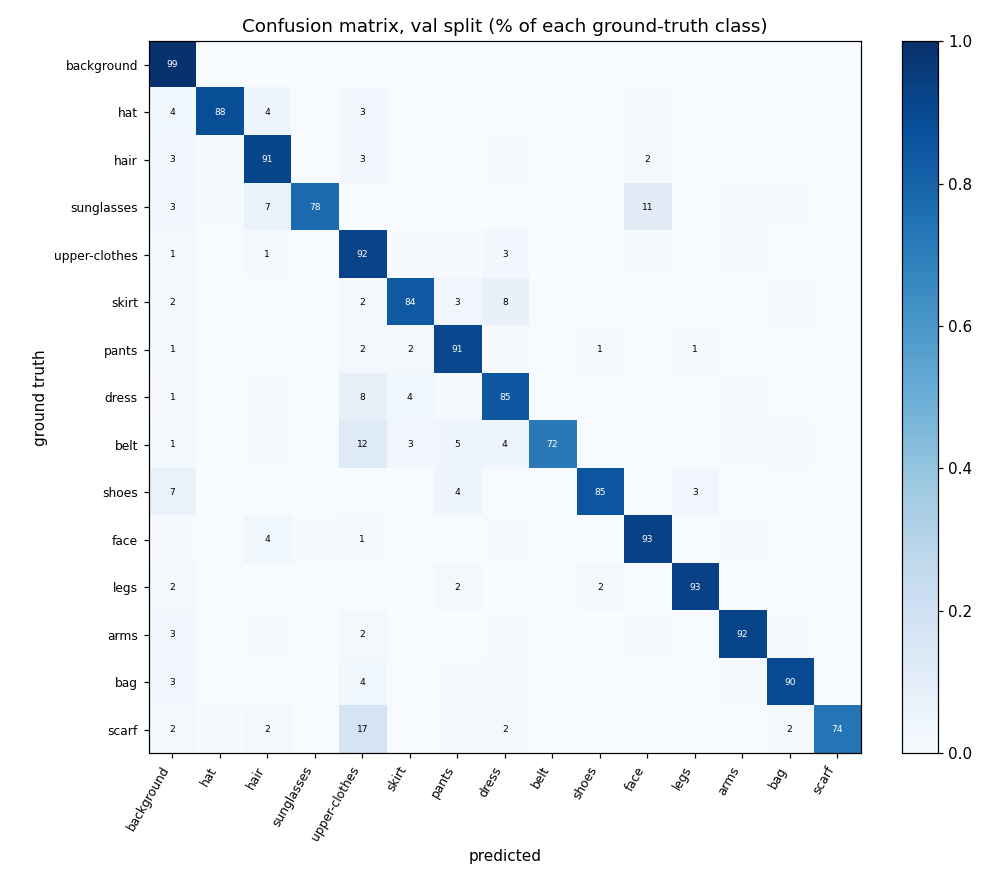

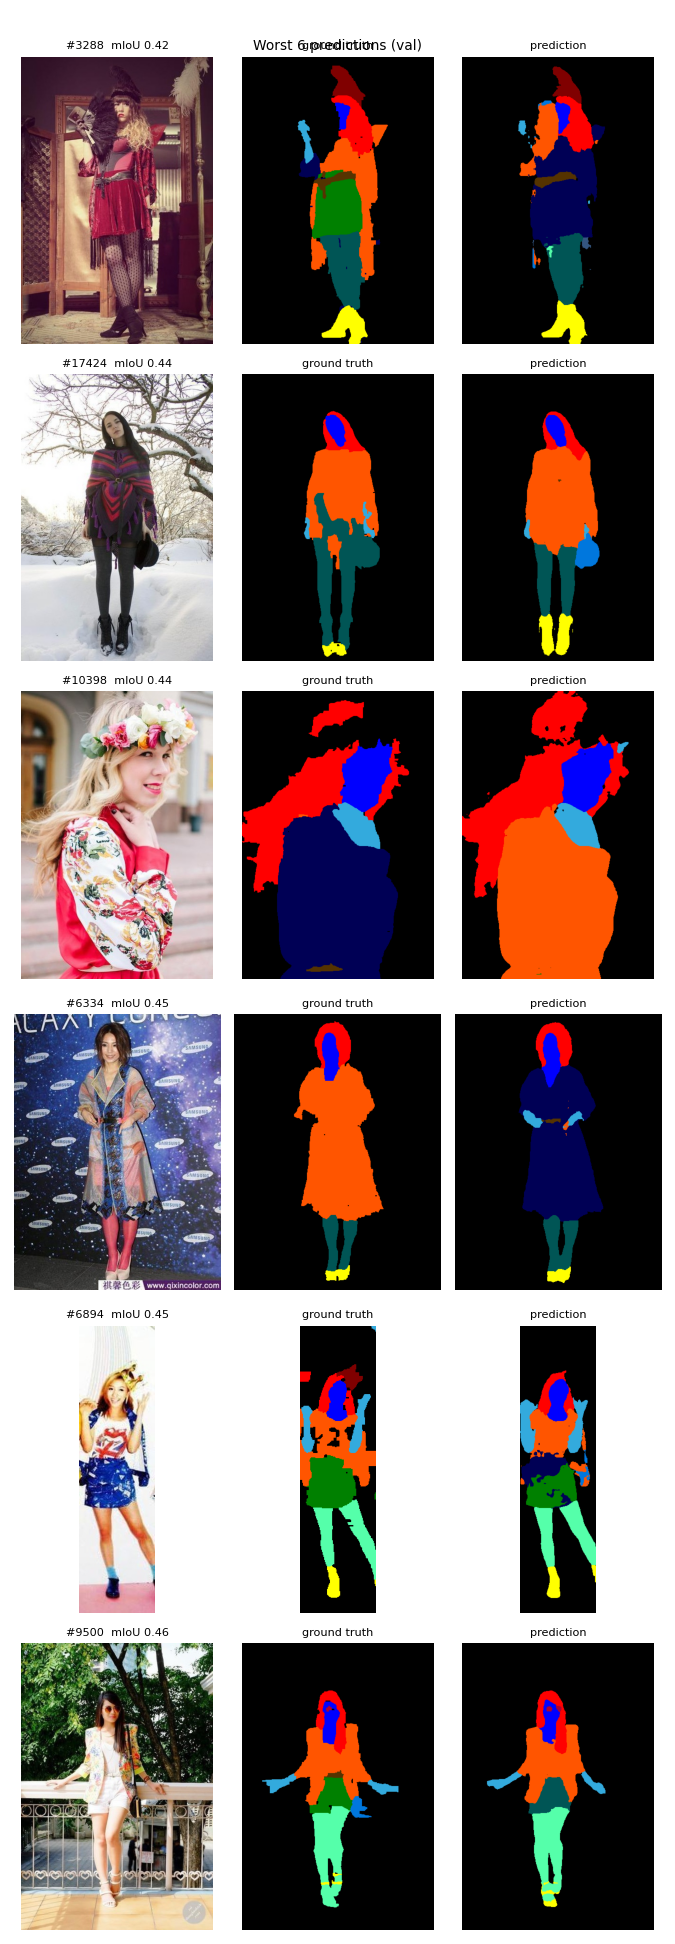

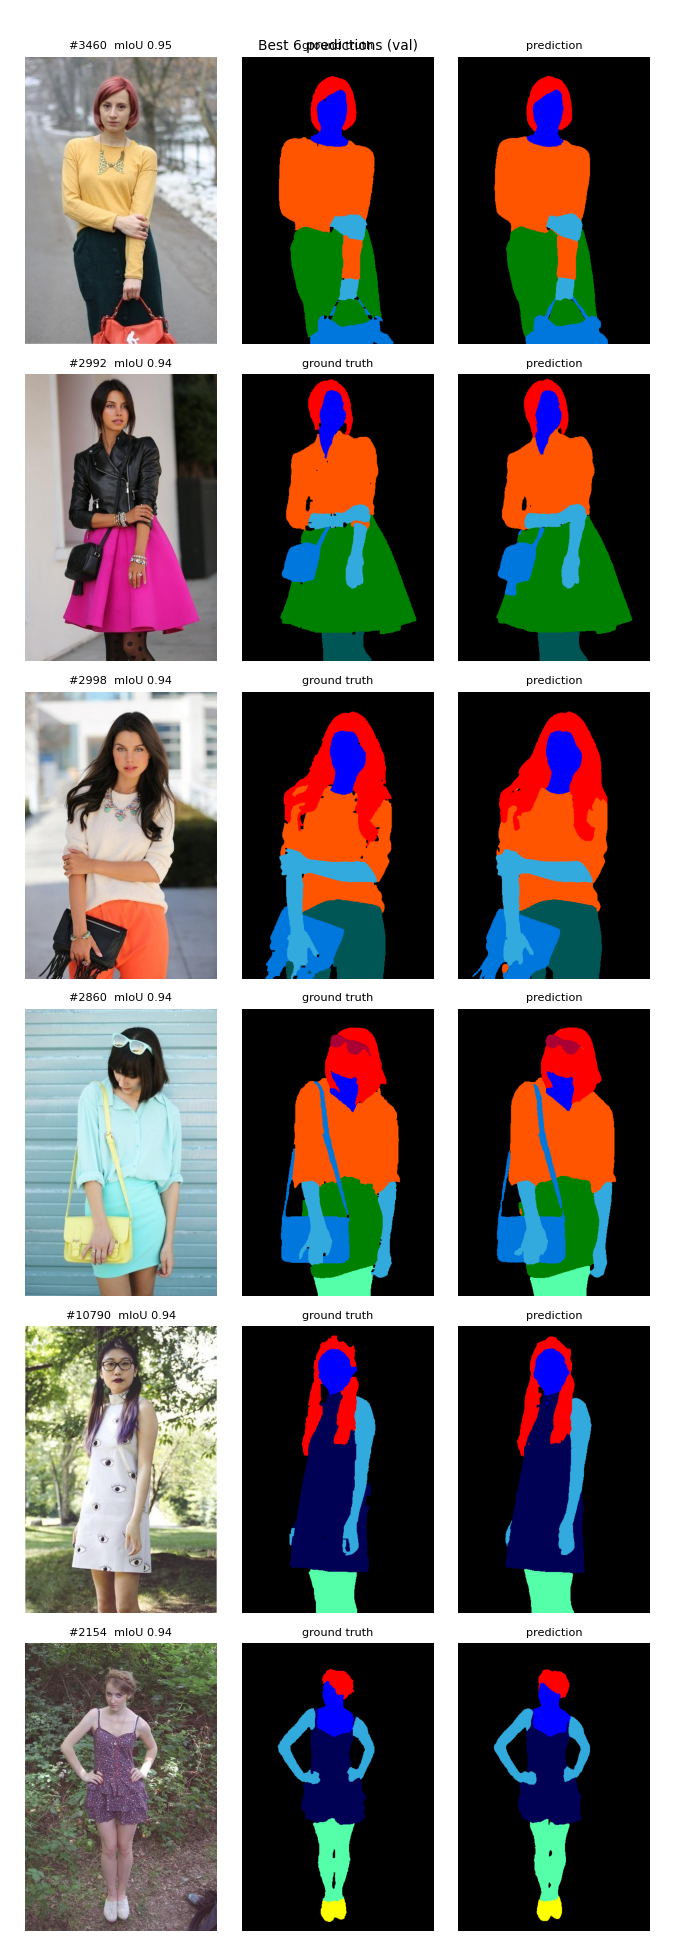

In [5]:
assert os.path.exists(CHECKPOINT), f"No checkpoint at {CHECKPOINT}. Check RUN_NAME, or wait until the run has finished its first epoch."
OUT = f"{DRIVE_ROOT}/reports/eval_{RUN_NAME}_val"
!python scripts/evaluate.py --checkpoint "{CHECKPOINT}" --split val --out-dir "{OUT}"

from IPython.display import Image, display
for name in ("confusion_matrix.png", "worst_examples.png", "best_examples.png"):
    display(Image(f"{OUT}/{name}"))

## 6. Segment your own photos

Upload one or more photos of a person. For each photo you get a label mask, a colour overlay and one transparent cut-out per garment.

Saving g4fdn.jpg to g4fdn.jpg
[model] segformer_b3: 47.2 M parameters (encoder 44.1 M, head 3.2 M) | 15 classes | weights not initialised from ImageNet
[segment] model segformer_b3, 15 classes, input 576x384, device cuda
[segment] 1/1 g4fdn.jpg (1280x720) 1476 ms | hair 4.7%, upper-clothes 14.3%, face 10.9% | cut-outs: upper-clothes
[segment] done: 1 ok, 0 failed. Results in /content/drive/MyDrive/clothseg/reports/segment_r1_segformer_b3
WhatsApp Image 2026-06-06 at 8.16.29 AM_overlay.jpg


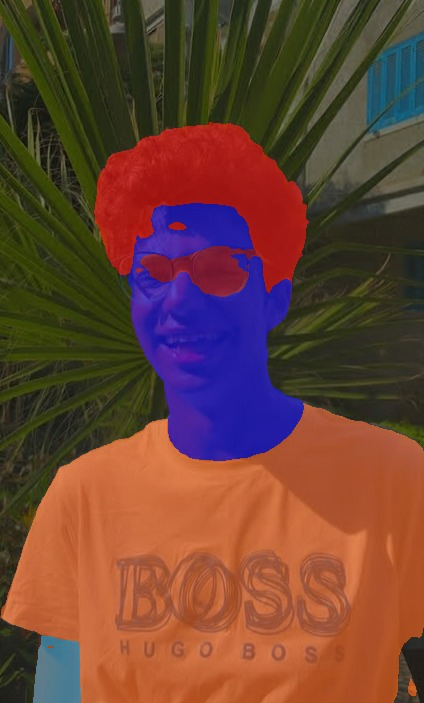

g4fdn_overlay.jpg


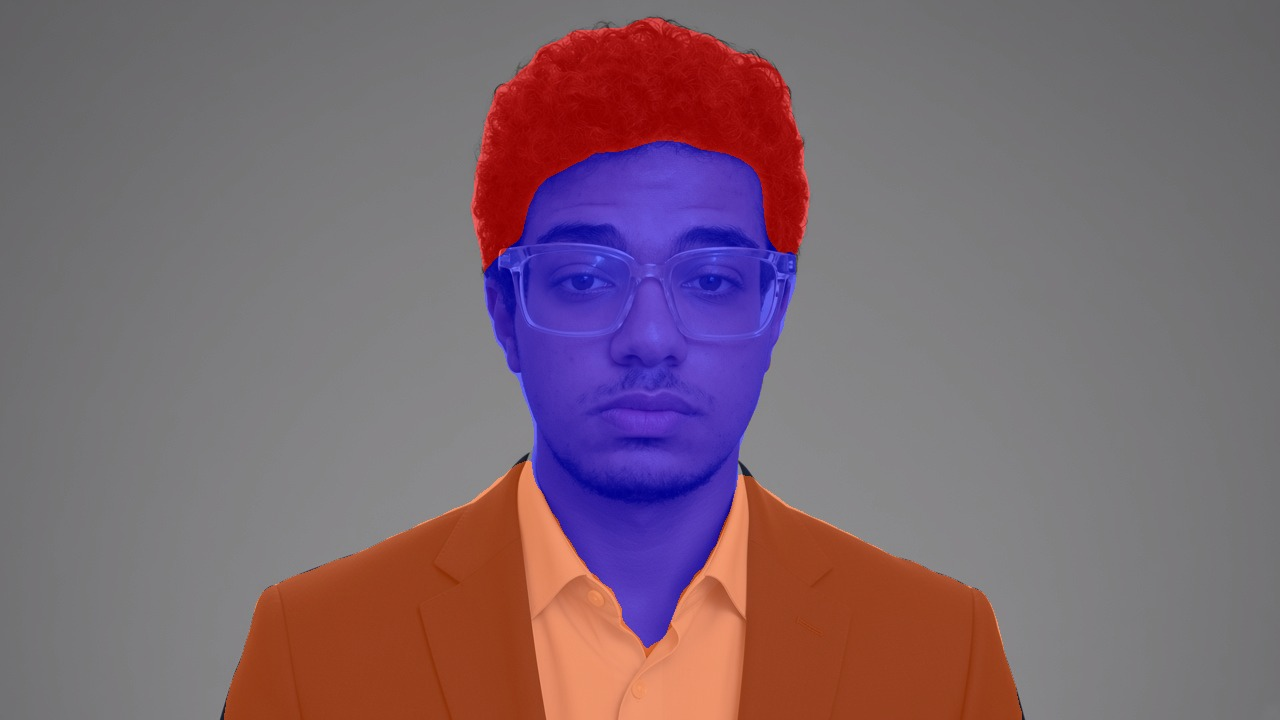

In [6]:
from google.colab import files
import glob

PHOTOS, RESULTS = "/content/my_photos", f"{DRIVE_ROOT}/reports/segment_{RUN_NAME}"
shutil.rmtree(PHOTOS, ignore_errors=True)
os.makedirs(PHOTOS)
os.chdir(PHOTOS)
uploaded = files.upload()
os.chdir(CODE_DIR)
assert uploaded, "No photo was uploaded."

!python scripts/segment.py --checkpoint "{CHECKPOINT}" --input "{PHOTOS}" --out-dir "{RESULTS}"

for path in sorted(glob.glob(f"{RESULTS}/*_overlay.jpg")):
    print(os.path.basename(path))
    display(Image(path, width=420))

## 7. Architecture experiment: SegFormer-B3 with an edge branch

Trains SegFormer-B3 with the added edge branch for 12 epochs, with the same data, seed and schedule as the baseline run `r1_segformer_b3`, then prints both side by side. About 2.5 hours. If the session ends, run cells 1 to 4 and this cell again.

In [7]:
EDGE_RUN = "abl_segformer_b3_edge"
gpu_gb = torch.cuda.get_device_properties(0).total_memory / 1024**3
assert gpu_gb >= 20, (f"This GPU has {gpu_gb:.0f} GB. Training needs the L4 (about 22 GB). "
                      "Choose Runtime > Change runtime type > L4 GPU, then run cells 1 to 4 and this cell again.")

os.chdir(CODE_DIR)
budget = int(minutes_left())
!python scripts/train.py --drive-root "{DRIVE_ROOT}" --run-name {EDGE_RUN} --model segformer_b3_edge --height {HEIGHT} --width {WIDTH} --epochs 12 --time-budget-min {budget}

import pandas as pd
cols = ["garment_miou", "miou", "iou_upper-clothes", "iou_pants", "iou_skirt", "iou_dress", "iou_belt", "iou_scarf", "val_loss", "train_min"]
base = pd.read_csv(f"{DRIVE_ROOT}/runs/r1_segformer_b3/val_log.csv").set_index("epoch")
assert os.path.exists(f"{DRIVE_ROOT}/runs/{EDGE_RUN}/val_log.csv"), "The edge run has not finished an epoch yet. Read the training output above for the reason."
edge = pd.read_csv(f"{DRIVE_ROOT}/runs/{EDGE_RUN}/val_log.csv").set_index("epoch")
print("\ngarment mIoU per epoch")
print(pd.DataFrame({"baseline B3": base["garment_miou"], "B3 + edge": edge["garment_miou"]}).to_string())
last = min(len(base), len(edge))
print(f"\nepoch {last}")
print(pd.DataFrame({"baseline B3": base.loc[last, cols], "B3 + edge": edge.loc[last, cols],
                    "difference": edge.loc[last, cols] - base.loc[last, cols]}).round(4).to_string())


pytorch_model.bin: downloading bytes:  54% 96.2M/179M [00:02<00:00, 85.6MB/s, 5.15MB/s  ]
pytorch_model.bin: downloading bytes:  71% 126M/179M [00:02<00:00, 116MB/s, 9.04MB/s  ]  
pytorch_model.bin: reconstructing file:  49% 87.7M/179M [00:02<00:02, 39.2MB/s, 6.32MB/s  ]
pytorch_model.bin: downloading bytes:  88% 158M/179M [00:02<00:00, 99.2MB/s, 13.8MB/s  ]
pytorch_model.bin: downloading bytes: 100% 168M/168M [00:02<00:00, 56.4MB/s, 15.0MB/s  ]
pytorch_model.bin: reconstructing file: 100% 179M/179M [00:02<00:00, 59.8MB/s, 16.2MB/s  ]
Loading weights: 100% 628/628 [00:00<00:00, 14366.64it/s]
[model] segformer_b3_edge: 48.0 M parameters (encoder 44.1 M, head 3.9 M) | 15 classes | encoder: ImageNet-pretrained weights loaded, head: new
[train] FRESH START in /content/drive/MyDrive/clothseg/runs/abl_segformer_b3_edge
[train] segformer_b3_edge | 15 classes | 576x384 | batch 16 | fp16 True | NVIDIA L4 | 8 workers
[train] data: train 16038, val 690 images (fingerprint 8b4d7a60ccb0) | 1002 st

## 8. Final training run

Trains the chosen model from the start with a longer schedule, as a new run. It takes several hours. If the session ends, run cells 1 to 4 and this cell again: it continues from the last checkpoint.

Set `FINAL_MODEL` to `"segformer_b3_edge"` only if we agreed that the edge model won the experiment above.

When it has finished, set `RUN_NAME` in cell 1 to the name printed below and run cells 5, 6 and 9 for the final model.

In [8]:
FINAL_MODEL, FINAL_EPOCHS = "segformer_b3", 30
FINAL_RUN = f"final_{FINAL_MODEL}_e{FINAL_EPOCHS}"
print("run name:", FINAL_RUN)
gpu_gb = torch.cuda.get_device_properties(0).total_memory / 1024**3
assert gpu_gb >= 20, (f"This GPU has {gpu_gb:.0f} GB. Training needs the L4 (about 22 GB). "
                      "Choose Runtime > Change runtime type > L4 GPU, then run cells 1 to 4 and this cell again.")

os.chdir(CODE_DIR)
budget = int(minutes_left())
!python scripts/train.py --drive-root "{DRIVE_ROOT}" --run-name {FINAL_RUN} --model {FINAL_MODEL} --height {HEIGHT} --width {WIDTH} --epochs {FINAL_EPOCHS} --time-budget-min {budget}

run name: final_segformer_b3_e30
Loading weights: 100% 628/628 [00:00<00:00, 23964.18it/s]
[model] segformer_b3: 47.2 M parameters (encoder 44.1 M, head 3.2 M) | 15 classes | encoder: ImageNet-pretrained weights loaded, head: new
[train] FRESH START in /content/drive/MyDrive/clothseg/runs/final_segformer_b3_e30
[train] segformer_b3 | 15 classes | 576x384 | batch 16 | fp16 True | NVIDIA L4 | 8 workers
[train] data: train 16038, val 690 images (fingerprint 8b4d7a60ccb0) | 1002 steps/epoch
[train] schedule: 30 epochs = 30060 steps; this command runs until the end of epoch 30; time budget 431 min; checkpoint every 10 min
[train] epoch 1/30 step 50/1002 | loss 1.7914 (ce 2.6621, lovasz 0.9206) | lr 2.00e-06 | 16.6 img/s | about 481 min left for this command (plus validation)
[train] epoch 1/30 step 100/1002 | loss 1.0555 (ce 1.3118, lovasz 0.7992) | lr 3.99e-06 | 23.8 img/s | about 335 min left for this command (plus validation)
[train] epoch 1/30 step 150/1002 | loss 0.5983 (ce 0.5770, lov

In [10]:
import json, os, pandas as pd

run = f"{DRIVE_ROOT}/runs/final_segformer_b3_e30"

status = f"{run}/status.json"
print(open(status).read() if os.path.exists(status) else "no status file yet")

v = pd.read_csv(f"{run}/val_log.csv")
print("\nepochs finished:", len(v), "of 30\n")
print(v[["epoch", "miou", "garment_miou", "iou_upper-clothes", "iou_pants", "iou_skirt",
         "iou_dress", "iou_belt", "iou_scarf", "val_loss", "train_min"]].to_string(index=False))

print("\ncheckpoints:", sorted(os.listdir(f"{run}/checkpoints")))


{
  "model": "segformer_b3",
  "epochs_done": 30,
  "epochs_total": 30,
  "global_step": 30060,
  "best_miou": 0.7866027892151131,
  "best_epoch": 28,
  "train_min": 336.2
}

epochs finished: 30 of 30

 epoch    miou  garment_miou  iou_upper-clothes  iou_pants  iou_skirt  iou_dress  iou_belt  iou_scarf  val_loss  train_min
     1 0.67580       0.60295            0.75204    0.75018    0.61703    0.60049   0.37990    0.32317   0.24564      11.47
     2 0.71735       0.65365            0.80060    0.77949    0.65050    0.64217   0.45622    0.45902   0.21634      22.69
     3 0.73242       0.67147            0.80887    0.80143    0.66154    0.66872   0.44602    0.48143   0.20231      33.88
     4 0.74216       0.68627            0.81585    0.79402    0.65712    0.66364   0.52122    0.52918   0.20095      45.09
     5 0.74568       0.68940            0.81422    0.79962    0.67235    0.67055   0.49502    0.50852   0.19467      56.32
     6 0.74999       0.69537            0.82706    0.81143  

## 9. Final test-set evaluation

**Run this once, only for the final model.** The test split must not be used to choose between models; if it is, its numbers are no longer an honest estimate.

evaluating val ...
evaluating val with flip averaging ...

VALIDATION  (690 images)
metric                      plain  with flip   change
miou                       0.7853     0.7888  +0.0036
garment_miou               0.7394     0.7441  +0.0047
core_garment_miou          0.7794     0.7904  +0.0110
clothing_binary_iou        0.9290     0.9296  +0.0006
pixel_acc                  0.9713     0.9720  +0.0007
mean_class_acc             0.8734     0.8755  +0.0021
mean_dice                  0.8762     0.8785  +0.0023
boundary_miou              0.7313     0.7349  +0.0036
garment_boundary_miou      0.6761     0.6808  +0.0046
ms_per_image              56.7265   104.0364 +47.3099

flip averaging changes validation mIoU by +0.36 points -> ADOPTED (rule: at least +0.20)
evaluating test ...
evaluating test with flip averaging ...

TEST  (960 images)
metric                      plain  with flip   change
miou                       0.7859     0.7886  +0.0026
garment_miou               0.7406     0.7439

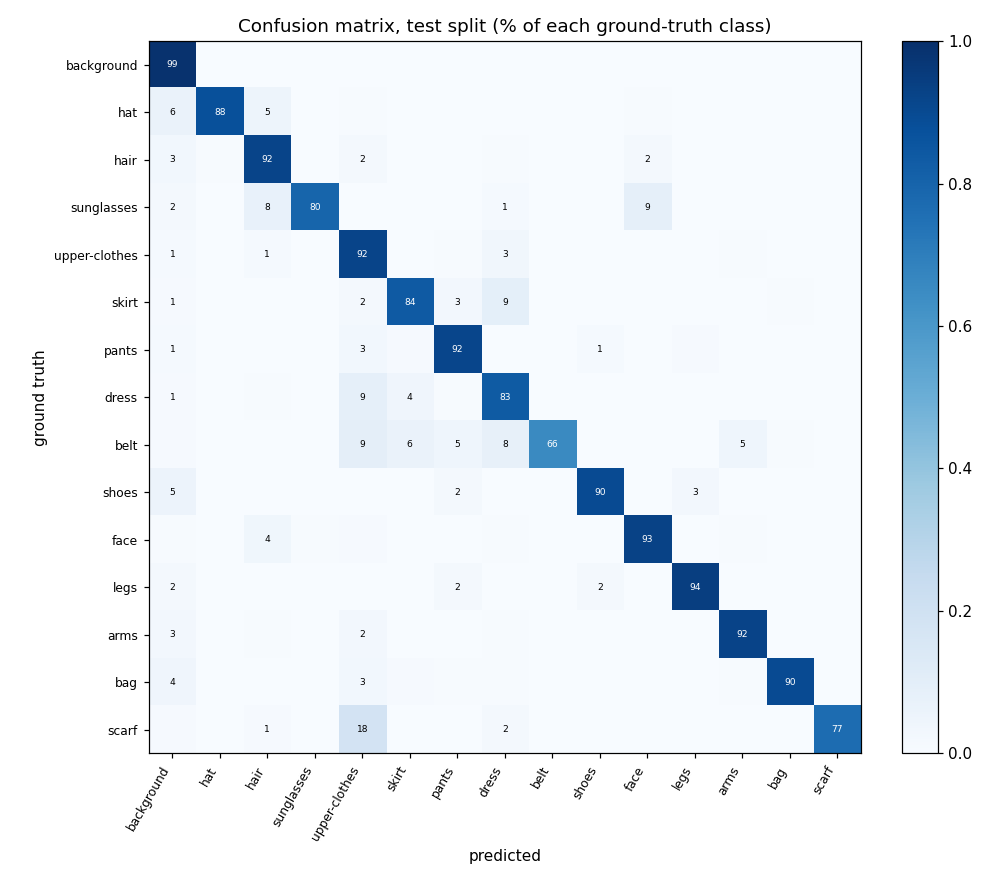

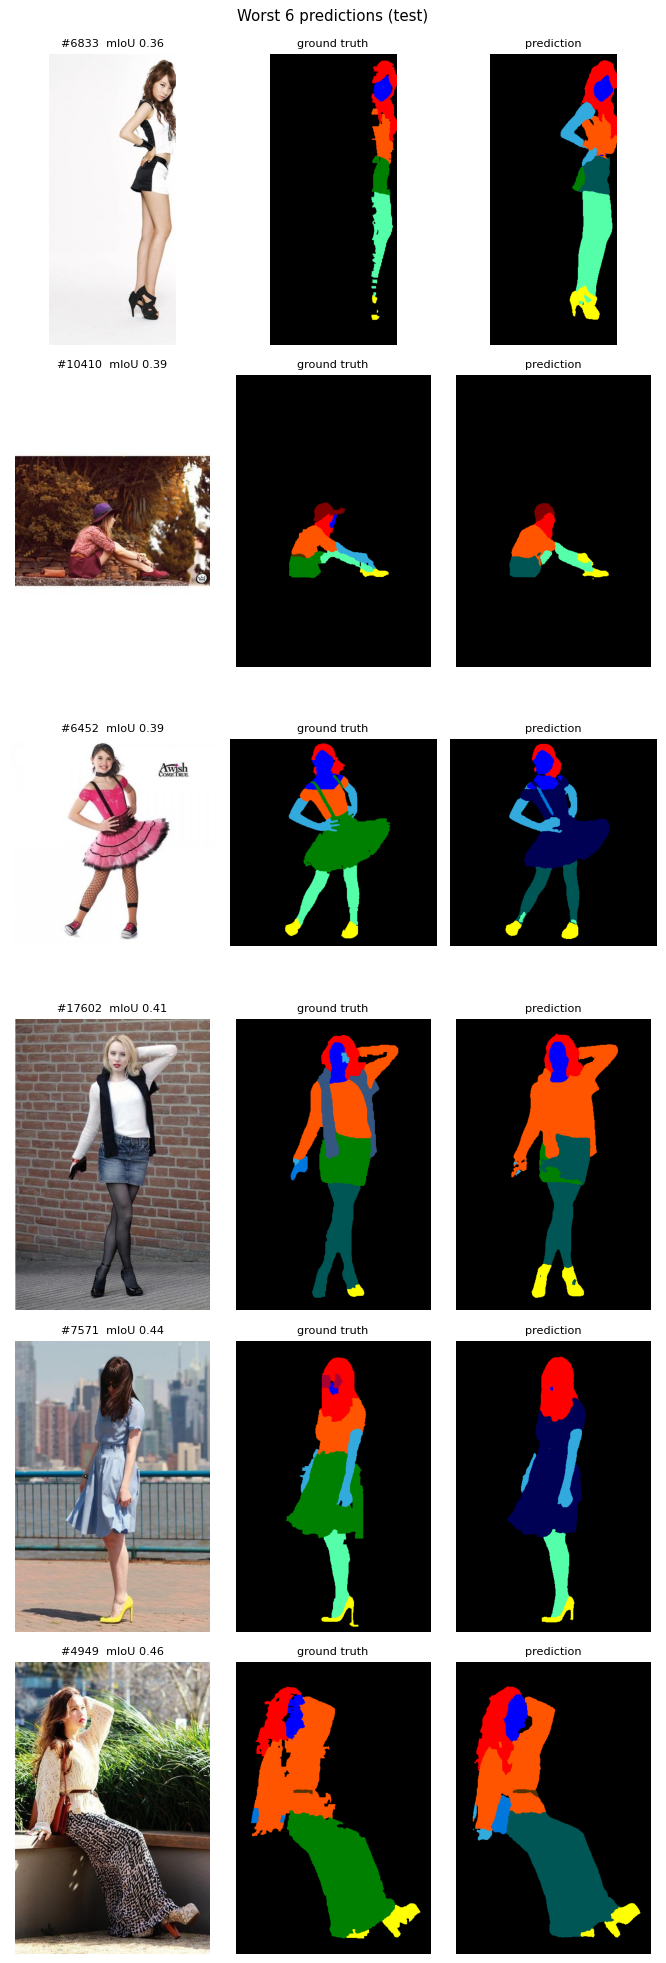

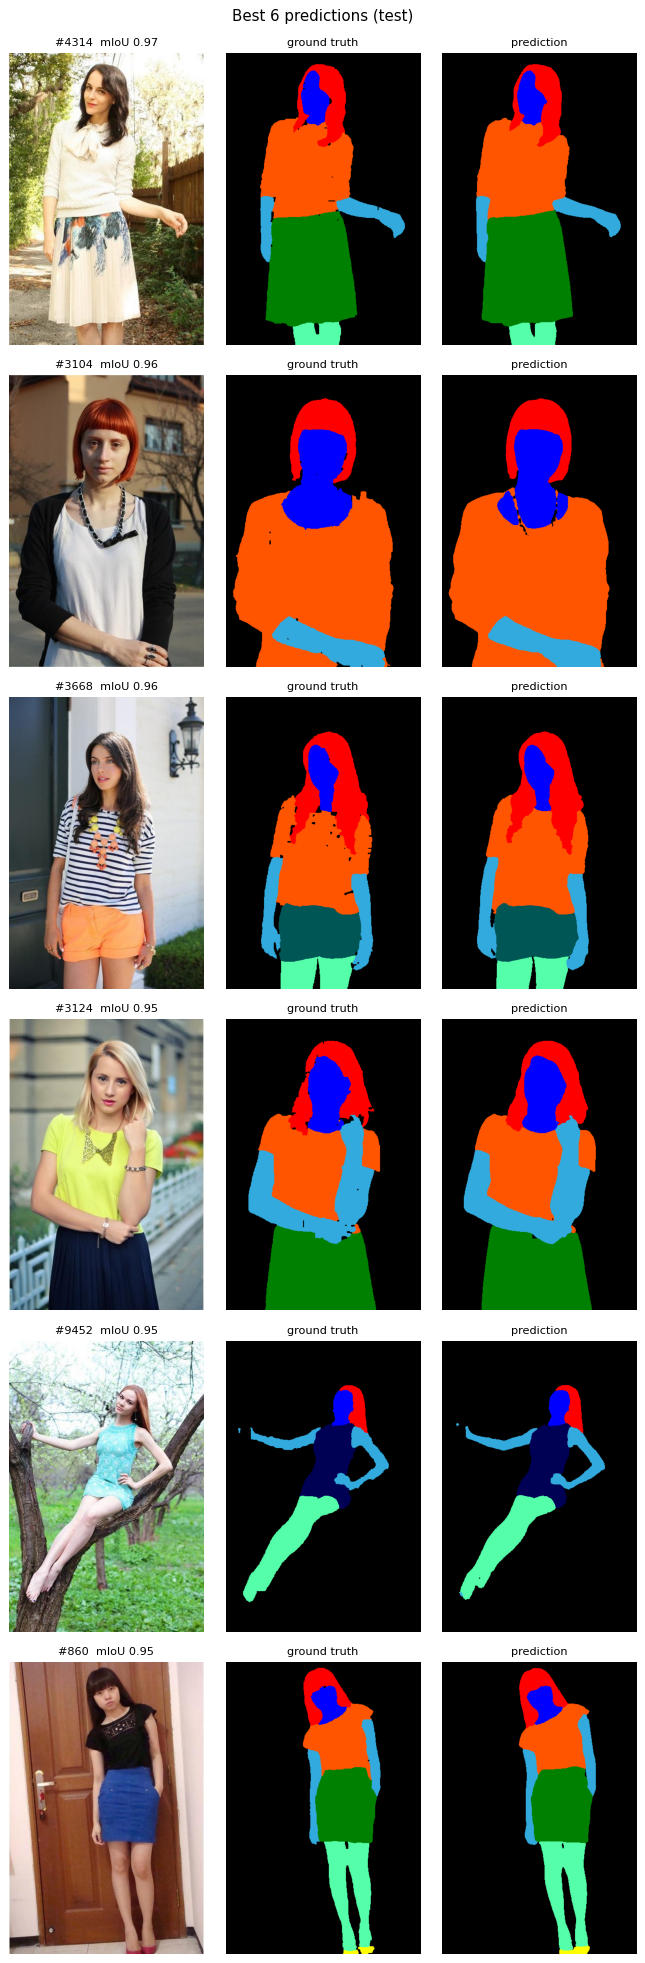

In [15]:
# Final evaluation of the final model. Paste this whole block into ONE new cell of
# notebooks/colab_eval.ipynb, after cells 1 to 4 have run, and run it once.
#
# What it does, in this order:
#   1. validation split, without and with flip averaging;
#   2. a safety check on the validation result;
#   3. decides on flip averaging by the rule fixed in PLAN.md, section 17.11;
#   4. test split, once, in both settings; prints and shows the results.

import json, os, subprocess, sys
import pandas as pd
from IPython.display import Image, display

RUN_NAME = "final_segformer_b3_e30"
CHECKPOINT = f"{DRIVE_ROOT}/runs/{RUN_NAME}/checkpoints/best.pt"
EXPECTED_VAL_MIOU = 0.7866      # validation mIoU of this checkpoint reported during training
FLIP_MIN_GAIN = 0.002           # flip averaging is adopted if it adds at least 0.2 points of mIoU

os.chdir(CODE_DIR)
assert os.path.exists(CHECKPOINT), f"No checkpoint at {CHECKPOINT}."
assert "--flip-tta" in open("scripts/evaluate.py").read(), (
    "This session has an older version of the code. Open the new colab_eval.ipynb from the project folder, "
    "run cells 1 to 4 (upload the new clothseg_code.zip when asked), then run this cell again.")


def evaluate(split, flip):
    """Run scripts/evaluate.py and return (metrics, output folder)."""
    out = f"{DRIVE_ROOT}/reports/eval_{RUN_NAME}_{split}" + ("_flip" if flip else "")
    cmd = [sys.executable, "scripts/evaluate.py", "--checkpoint", CHECKPOINT, "--split", split, "--out-dir", out]
    print(f"evaluating {split}{' with flip averaging' if flip else ''} ...", flush=True)
    r = subprocess.run(cmd + (["--flip-tta"] if flip else []), capture_output=True, text=True)
    assert r.returncode == 0, "The evaluation failed. Send me this message:\n" + (r.stdout + r.stderr)[-3000:]
    return json.load(open(f"{out}/metrics.json")), out


KEYS = ("miou", "garment_miou", "core_garment_miou", "clothing_binary_iou", "pixel_acc", "mean_class_acc",
        "mean_dice", "boundary_miou", "garment_boundary_miou", "ms_per_image")


def table(title, plain, flip):
    print(f"\n{title}  ({plain['num_images']} images)")
    print(f"{'metric':<24}{'plain':>9}{'with flip':>11}{'change':>9}")
    for k in KEYS:
        print(f"{k:<24}{plain[k]:>9.4f}{flip[k]:>11.4f}{flip[k] - plain[k]:>+9.4f}")


# 1. Validation.
val_plain, _ = evaluate("val", False)
val_flip, _ = evaluate("val", True)
table("VALIDATION", val_plain, val_flip)

# 2. Safety check before the test set is touched.
assert abs(val_plain["miou"] - EXPECTED_VAL_MIOU) < 0.01, (
    f"Validation mIoU is {val_plain['miou']:.4f}, expected about {EXPECTED_VAL_MIOU}. "
    "Something is wrong. The test set was NOT used. Send me the output above.")

# 3. Decision on flip averaging, from validation only.
gain = val_flip["miou"] - val_plain["miou"]
use_flip = gain >= FLIP_MIN_GAIN
print(f"\nflip averaging changes validation mIoU by {100 * gain:+.2f} points -> "
      + ("ADOPTED (rule: at least +0.20)" if use_flip else "NOT adopted (rule: at least +0.20)"))

# 4. Test split, once.
test_plain, out_plain = evaluate("test", False)
test_flip, out_flip = evaluate("test", True)
table("TEST", test_plain, test_flip)
head, head_dir = (test_flip, out_flip) if use_flip else (test_plain, out_plain)
print(f"\nHEADLINE TEST RESULT ({'with' if use_flip else 'without'} flip averaging): "
      f"mIoU {head['miou']:.4f} | garment mIoU {head['garment_miou']:.4f} | clothing binary IoU {head['clothing_binary_iou']:.4f} | "
      f"pixel accuracy {head['pixel_acc']:.4f} | boundary mIoU {head['boundary_miou']:.4f}")

print("\nPer-class results of the headline test evaluation")
print(pd.read_csv(f"{head_dir}/per_class.csv").round(4).to_string(index=False))
print(f"\nfiles saved in {head_dir}")
for name in ("confusion_matrix.png", "worst_examples.png", "best_examples.png"):
    display(Image(f"{head_dir}/{name}"))


## What to send back

The text output of cell 5 and a note on how the overlays in cell 6 look (which garments are right, which are wrong).